<a href="https://colab.research.google.com/github/LeonardooAlves/LSE-ST445/blob/main/Week%207/2_st445_week8_lab2_eda_challenge_SOLUTIONS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ST445 Week 8 · Lab 2: the EDA challenge


**A team game · about 100 minutes · practises the Week 7 EDA protocol and the Week 8 matrix methods on one dataset**

Two teams, **Team A** and **Team B**, answer questions about the same dataset using exploratory data analysis. After each round, each team **evaluates the other team's answer**: could they understand it clearly, vaguely, or not at all? Points go to the team whose answer was understood. The team with more points at the end wins.

### How a round works (10 minutes)

| Time | What happens |
|---|---|
| 6 minutes | Each team answers **its own question card** (Team A answers card A, Team B card B): code, one chart, and an insight statement |
| 2 minutes | Each team's **presenter** shows the chart and reads the insight statement to the other team (in person, or by sharing the screen) |
| 2 minutes | Each team **scores the other team's answer** with the rubric below, and records the score and a one-line reason |

The two cards in each round practise the **same skill** on different variables, so the round is fair and the teams cannot copy each other. There are **8 rounds** (40 minutes per four rounds, with a 10-minute break between rounds 4 and 5), then a **final question** for both teams, scored by the tutor as a tie-break.

### Scoring rubric: use it for every evaluation

| Points | The other team's answer was ... | In practice |
|---|---|---|
| **1** | understood **clearly** | it answers the question; it states an **observation**, gives specific **evidence** (the chart, with at least one number), and states a **caveat**; the chart is readable (title, labelled axes with units, suitable colours) |
| **0.5** | understood **vaguely** | it answers the question, but the evidence has no number, or the caveat is missing, or the chart is hard to read |
| **0** | **not understood** | it does not answer the question, or it is wrong, or there is no chart or no statement |

**Fair play.** Score the **clarity of the explanation**, not whether you agree with it. Every score needs a one-line reason; a team that disagrees with a score may appeal to the tutor, whose decision is final.

### Roles: rotate them every round

* **Analyst:** writes the code.
* **Writer:** writes the insight statement (observation, evidence, caveat).
* **Presenter:** presents the answer, and leads the scoring of the other team's answer.

With three people per team, everyone takes every role at least twice.

**Before you start:** choose **File → Save a copy in Drive**, and fill in your team details in section 1.

---
## 1. Your team

In [1]:
# 🟢 Fill in, then run
MY_TEAM = "A"                                  # "A" or "B"
TEAM_NAME = "____"                             # a name for the leaderboard
MEMBERS = ["____", "____", "____"]             # in the order you will rotate roles

OTHER_TEAM = "B" if MY_TEAM == "A" else "A"
ROLES = ["analyst", "writer", "presenter"]
for r in range(1, 9):
    rotation = {ROLES[i]: MEMBERS[(r - 1 + i) % len(MEMBERS)] for i in range(3)}
    print(f"round {r}: {rotation}")

round 1: {'analyst': '____', 'writer': '____', 'presenter': '____'}
round 2: {'analyst': '____', 'writer': '____', 'presenter': '____'}
round 3: {'analyst': '____', 'writer': '____', 'presenter': '____'}
round 4: {'analyst': '____', 'writer': '____', 'presenter': '____'}
round 5: {'analyst': '____', 'writer': '____', 'presenter': '____'}
round 6: {'analyst': '____', 'writer': '____', 'presenter': '____'}
round 7: {'analyst': '____', 'writer': '____', 'presenter': '____'}
round 8: {'analyst': '____', 'writer': '____', 'presenter': '____'}


### Imports, style and the scoring tool

The cell below also defines `award(round_number, points, reason)`, which records the score **your team gives the other team** after each round, and `scoreboard()`, which shows the totals.

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, optimal_leaf_ordering, leaves_list, fcluster
from scipy.spatial.distance import squareform, pdist
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.neighbors import kneighbors_graph

OKABE_ITO = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00", "#F0E442", "#000000"]
ORIGIN_COLOURS = {"usa": OKABE_ITO[0], "europe": OKABE_ITO[1], "japan": OKABE_ITO[2]}
sns.set_theme(style="ticks")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

SCORES_GIVEN = {}                              # round -> {"points": ..., "reason": ...}

def award(round_number, points, reason):
    """Record the score your team gives the OTHER team's answer in a round."""
    assert points in (0, 0.5, 1), "points must be 0, 0.5 or 1 (see the rubric)"
    assert len(reason.strip()) >= 10, "give a one-line reason for the score"
    SCORES_GIVEN[round_number] = {"points": points, "reason": reason.strip()}
    print(f"Round {round_number}: Team {OTHER_TEAM} receives {points} point(s). Reason: {reason.strip()}")

def scoreboard():
    """The scores your team has given, as a table, and their total."""
    table = pd.DataFrame(SCORES_GIVEN).T.rename_axis("round")
    total = table["points"].sum() if len(table) else 0
    print(f"Points given to Team {OTHER_TEAM} so far: {total}")
    return table

---
## 2. The dataset: Auto MPG

Fuel consumption and design of **398 cars** sold in the United States between **1970 and 1982**: fuel economy (miles per US gallon, **mpg**: higher is better), number of cylinders, engine displacement (cubic inches), horsepower, weight (pounds), acceleration (seconds from 0 to 60 mph: **lower is faster**), model year, origin (USA, Europe or Japan) and name.

* **Source:** Quinlan, J. R. (1993), "Combining instance-based and model-based learning", *Proceedings of the Tenth International Conference on Machine Learning*, 236–243; [UCI Machine Learning Repository, dataset 9](https://archive.ics.uci.edu/dataset/9/auto+mpg), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Loaded with [`sns.load_dataset("mpg")`](https://seaborn.pydata.org/generated/seaborn.load_dataset.html).
* **Why this dataset:** it needs almost no preprocessing, has a time dimension (model year), groups (origin, cylinders), a few genuinely missing values, a famous outlier, and seven numeric variables for matrix displays.

### Preprocessing, in one cell

In [3]:
# 🟢 Load and prepare the data: one documented cell
raw = sns.load_dataset("mpg")                 # downloads a copy of the UCI file (internet needed)
cars = raw.copy()                             # keep raw unchanged

# 1. The real model year, instead of two digits (70 -> 1970)
cars["year"] = 1900 + cars["model_year"]
cars = cars.drop(columns="model_year")

# 2. Origin as a category with a fixed order, so every chart uses the same order and colours
cars["origin"] = pd.Categorical(cars["origin"], categories=["usa", "europe", "japan"])

# 3. The make (brand), the first word of the name, with the dataset's misspellings corrected
cars["make"] = (cars["name"].str.split().str[0]
                .replace({"chevy": "chevrolet", "chevroelt": "chevrolet", "vw": "volkswagen",
                          "vokswagen": "volkswagen", "toyouta": "toyota", "maxda": "mazda",
                          "mercedes-benz": "mercedes"}))

# 4. Horsepower is missing for 6 cars. We do NOT impute it here: round 2 asks you to examine
#    the gaps. 'complete' keeps only cars with every value, for the matrix methods (rounds 6 to 8)
NUMERIC = ["mpg", "cylinders", "displacement", "horsepower", "weight", "acceleration", "year"]
complete = cars.dropna(subset=NUMERIC).reset_index(drop=True)

# 5. A standardised copy (mean 0, sd 1) for distances between cars, so that no variable
#    dominates because of its units (weight in thousands of pounds would swamp everything else)
Z = (complete[NUMERIC] - complete[NUMERIC].mean()) / complete[NUMERIC].std()

# 6. Checks that fail loudly
assert cars.shape[0] == 398, "unexpected number of cars"
assert complete[NUMERIC].notna().all().all() and len(complete) == 392, "unexpected missing values"

print("all cars:", cars.shape, "| complete cars:", complete.shape)
cars.head()

all cars: (398, 10) | complete cars: (392, 10)


,mpg,cylinders,displacement,horsepower,weight,acceleration,origin,name,year,make
0,18.0,8,307.0,130.0,3504,12.0,usa,chevrolet chevelle malibu,1970,chevrolet
1,15.0,8,350.0,165.0,3693,11.5,usa,buick skylark 320,1970,buick
2,18.0,8,318.0,150.0,3436,11.0,usa,plymouth satellite,1970,plymouth
3,16.0,8,304.0,150.0,3433,12.0,usa,amc rebel sst,1970,amc
4,17.0,8,302.0,140.0,3449,10.5,usa,ford torino,1970,ford


**What you should see:** 398 cars in `cars` and 392 in `complete` (the 6 without horsepower removed). Use **`cars`** for Week 7 questions and **`complete`** and **`Z`** for the matrix questions.

### Your toolkit: helper functions from the Week 8 lecture

These are ready to use, so that you can spend the rounds on analysis rather than on writing algorithms.

In [4]:
# 🟢 Week 8 helpers
def ar_events(D):
    """Gradient-condition violations (anti-Robinson events) of a dissimilarity matrix in its current order."""
    D = np.asarray(D)
    n = len(D)
    count = 0
    for i in range(n):
        for j in range(i + 2, n):
            k = np.arange(i + 1, j)
            count += int((D[i, k] > D[i, j]).sum()) + int((D[k, j] > D[i, j]).sum())
    return count

def seriate(D, method="average"):
    """An order for a dissimilarity matrix: hierarchical clustering + optimal leaf ordering."""
    condensed = squareform(np.asarray(D), checks=False)
    tree = optimal_leaf_ordering(linkage(condensed, method), condensed)
    return leaves_list(tree)

def fiedler_order(X, n_neighbors=10):
    """Spectral seriation: the Fiedler vector of a nearest-neighbour graph, and the order it gives."""
    A = kneighbors_graph(X, n_neighbors=n_neighbors, mode="connectivity").toarray()
    S = (A + A.T) / 2
    L = np.diag(S.sum(axis=1)) - S
    values, vectors = np.linalg.eigh(L)
    fiedler = vectors[:, 1]
    return fiedler, np.argsort(fiedler)

print("toolkit ready: ar_events(D), seriate(D), fiedler_order(X)")

toolkit ready: ar_events(D), seriate(D), fiedler_order(X)


### How to write each answer

For every card: one code cell that produces **one clear chart** (and any numbers you need), then the Markdown answer cell, completed:

> **Observation:** what you found, in one sentence that answers the question.
> **Evidence:** the chart, and at least one number from your output.
> **Caveat:** one thing that could make the observation wrong, or narrower.

Week 7's checklist applies to the chart: a title that states the finding, labelled axes with units, a suitable colour scale, and bars that start at zero.

---
## Round 1 · Week 7 · step 2: univariate distributions

**Hint for both cards:** `sns.histplot`, with a reference line at the median (`ax.axvline`); `.describe()` and `.skew()` for the numbers.

### Card A (Team A answers)

**Question.** How is **fuel economy (`mpg`)** distributed across the 398 cars? What is a typical value, how widely does it vary, and is the distribution symmetric?

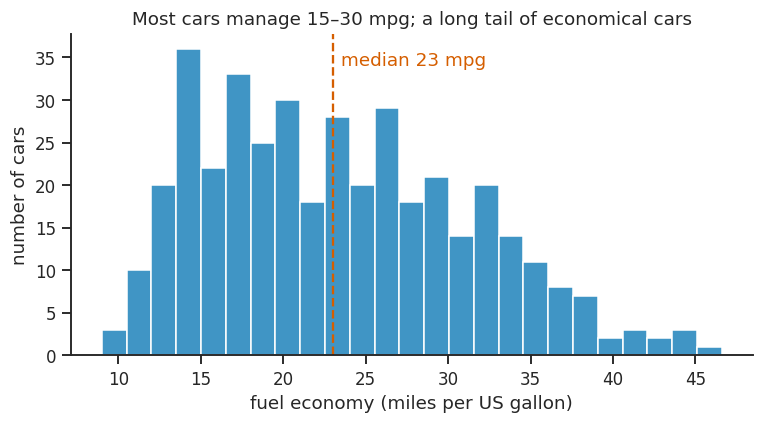

{'count': 398.0, 'mean': 23.5, 'std': 7.8, 'min': 9.0, '25%': 17.5, '50%': 23.0, '75%': 29.0, 'max': 46.6} skew: 0.46


In [5]:
# Model answer, card A, round 1
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.histplot(data=cars, x="mpg", bins=25, color=OKABE_ITO[0], ax=ax)
median = cars["mpg"].median()
ax.axvline(median, color=OKABE_ITO[5], linestyle="--")
ax.text(median + 0.5, ax.get_ylim()[1] * 0.9, f"median {median:.0f} mpg", color=OKABE_ITO[5])
ax.set(title="Most cars manage 15–30 mpg; a long tail of economical cars", xlabel="fuel economy (miles per US gallon)", ylabel="number of cars")
plt.show()
print(cars["mpg"].describe().round(1).to_dict(), "skew:", round(cars["mpg"].skew(), 2))

**Model answer, card A, round 1**

**Observation:** fuel economy is moderately right-skewed: most cars achieve 15–30 mpg, with a tail of economical cars up to 46.6 mpg. **Evidence:** histogram; median 23 mpg, mean 23.5, middle half between 17.5 and 29 mpg, skewness 0.46. **Caveat:** the data mix 13 model years in which fuel economy improved a great deal (round 5), so a single 'typical' value hides a trend.

### Card B (Team B answers)

**Question.** How is **horsepower** distributed across the cars? What is a typical value, how widely does it vary, and is the distribution symmetric?

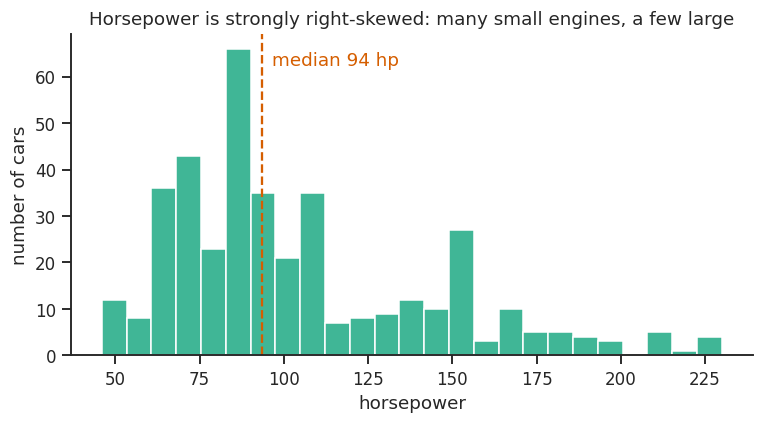

{'count': 392.0, 'mean': 104.5, 'std': 38.5, 'min': 46.0, '25%': 75.0, '50%': 93.5, '75%': 126.0, 'max': 230.0} skew: 1.09


In [6]:
# Model answer, card B, round 1
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.histplot(data=cars, x="horsepower", bins=25, color=OKABE_ITO[2], ax=ax)
median = cars["horsepower"].median()
ax.axvline(median, color=OKABE_ITO[5], linestyle="--")
ax.text(median + 3, ax.get_ylim()[1] * 0.9, f"median {median:.0f} hp", color=OKABE_ITO[5])
ax.set(title="Horsepower is strongly right-skewed: many small engines, a few large", xlabel="horsepower", ylabel="number of cars")
plt.show()
print(cars["horsepower"].describe().round(1).to_dict(), "skew:", round(cars["horsepower"].skew(), 2))

**Model answer, card B, round 1**

**Observation:** horsepower is strongly right-skewed: most cars have 70–130 hp, with a tail of powerful cars up to 230 hp. **Evidence:** histogram; median 93.5 hp against a mean of 104.5 (pulled up by the tail), skewness 1.09. **Caveat:** 6 cars have no horsepower recorded and are not in the chart (round 2); the median is a better summary than the mean.

In [7]:
# Score the OTHER team's answer for round 1 (0, 0.5 or 1), with a one-line reason
# award(1, 1, "clear observation; evidence with numbers; caveat about ...")

---
## Round 2 · Week 7 · steps 3 and 7: missingness and anomalies

**Hint for both cards:** A: `cars.isna().sum()`, then look at the rows with missing horsepower (origin, year). B: a scatter of acceleration against horsepower, and label the points furthest from the trend (`np.polyfit` or by eye).

### Card A (Team A answers)

**Question.** Which values are **missing** in the dataset, for which cars, and could the gaps **bias** an analysis of horsepower?

{'horsepower': 6}
                name  year origin  mpg
          ford pinto  1971    usa 25.0
       ford maverick  1974    usa 21.0
renault lecar deluxe  1980 europe 40.9
  ford mustang cobra  1980    usa 23.6
         renault 18i  1981 europe 34.5
      amc concord dl  1982    usa 23.0


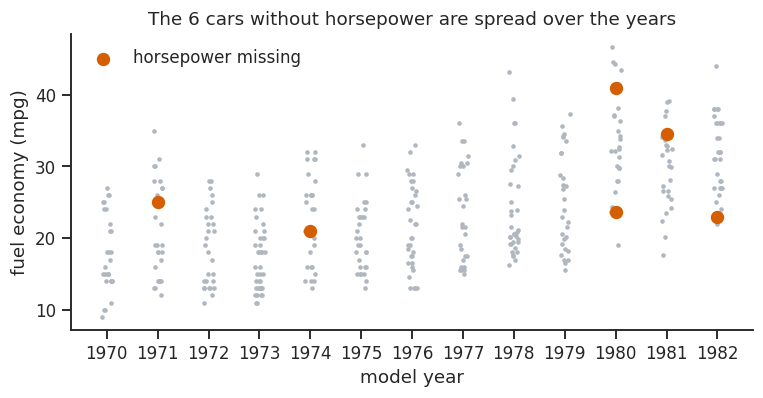

In [8]:
# Model answer, card A, round 2
missing = cars[cars["horsepower"].isna()]
print(cars.isna().sum()[cars.isna().sum() > 0].to_dict())
print(missing[["name", "year", "origin", "mpg"]].to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.stripplot(data=cars, x="year", y="mpg", color="#B0B7BF", size=3, ax=ax)
ax.scatter(missing["year"] - 1970, missing["mpg"], color=OKABE_ITO[5], s=60, zorder=3, label="horsepower missing")
ax.legend(frameon=False)
ax.set(title="The 6 cars without horsepower are spread over the years", xlabel="model year", ylabel="fuel economy (mpg)")
plt.show()

**Model answer, card A, round 2**

**Observation:** only horsepower has missing values, for 6 of 398 cars (1.5%): four American and two European, from 1971 to 1982, with fuel economy between 21 and 41 mpg. **Evidence:** `isna().sum()` and the list of the 6 cars; the chart shows them spread across years rather than in one block. **Caveat:** 6 cars are too few to bias overall summaries noticeably, but 4 of the 6 are from 1980–82, so averages for those years have slightly fewer cars; dropping them for the matrix analysis is a decision to log.

### Card B (Team B answers)

**Question.** Which cars are **unusual**: much slower or faster to accelerate than their **horsepower** would suggest? Are they errors or genuine?

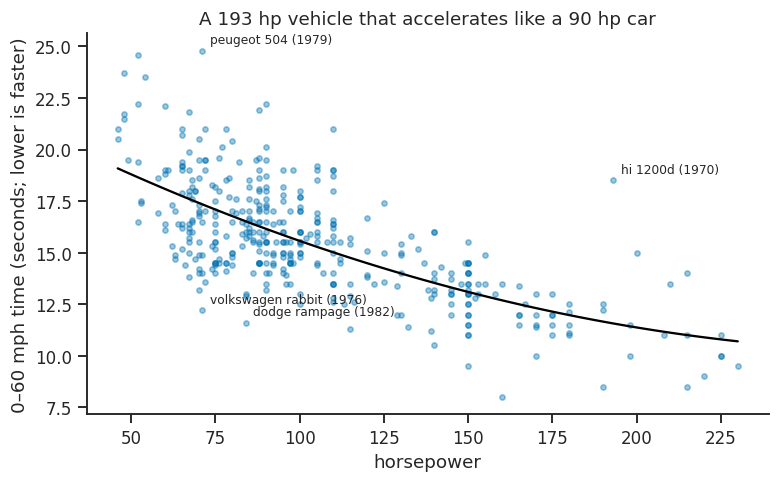

             name  year  horsepower  acceleration  residual
      peugeot 504  1979        71.0          24.8       7.4
         hi 1200d  1970       193.0          18.5       6.9
volkswagen rabbit  1976        71.0          12.2      -5.2
    dodge rampage  1982        84.0          11.6      -4.9


In [9]:
# Model answer, card B, round 2
c = cars.dropna(subset=["horsepower"]).copy()
trend = np.poly1d(np.polyfit(c["horsepower"], c["acceleration"], 2))      # a smooth curve through the cloud
c["residual"] = c["acceleration"] - trend(c["horsepower"])
unusual = pd.concat([c.nlargest(2, "residual"), c.nsmallest(2, "residual")])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(c["horsepower"], c["acceleration"], s=12, alpha=0.4, color=OKABE_ITO[0])
xs = np.linspace(c["horsepower"].min(), c["horsepower"].max(), 100)
ax.plot(xs, trend(xs), color="black", linewidth=1.5)
for _, row in unusual.iterrows():
    ax.annotate(f"{row['name']} ({row['year']})", (row["horsepower"], row["acceleration"]), fontsize=8,
                xytext=(5, 5), textcoords="offset points")
ax.set(title="A 193 hp vehicle that accelerates like a 90 hp car", xlabel="horsepower", ylabel="0–60 mph time (seconds; lower is faster)")
plt.show()
print(unusual[["name", "year", "horsepower", "acceleration", "residual"]].round(1).to_string(index=False))

**Model answer, card B, round 2**

**Observation:** the 'hi 1200d' (1970) has 193 hp but takes 18.5 s to reach 60 mph, far slower than its power suggests; the Peugeot 504 (1979) is also slow for its 71 hp (24.8 s). **Evidence:** scatter with a fitted curve; the Peugeot lies about 7.4 s and the hi 1200d about 6.9 s above the curve. **Caveat:** the hi 1200d is an International Harvester pickup truck, so it is genuine but a different kind of vehicle (heavy), not an error: keep it, and note it.

In [10]:
# Score the OTHER team's answer for round 2 (0, 0.5 or 1), with a one-line reason
# award(2, 1, "clear observation; evidence with numbers; caveat about ...")

---
## Round 3 · Week 7 · step 4: relationships

**Hint for both cards:** A scatter plot first (`sns.regplot` with `lowess=True` or `order=2` shows the shape), then a correlation (`.corr()`). Remember Anscombe.

### Card A (Team A answers)

**Question.** How are **weight** and **fuel economy** related? Describe the direction, the strength and the shape.

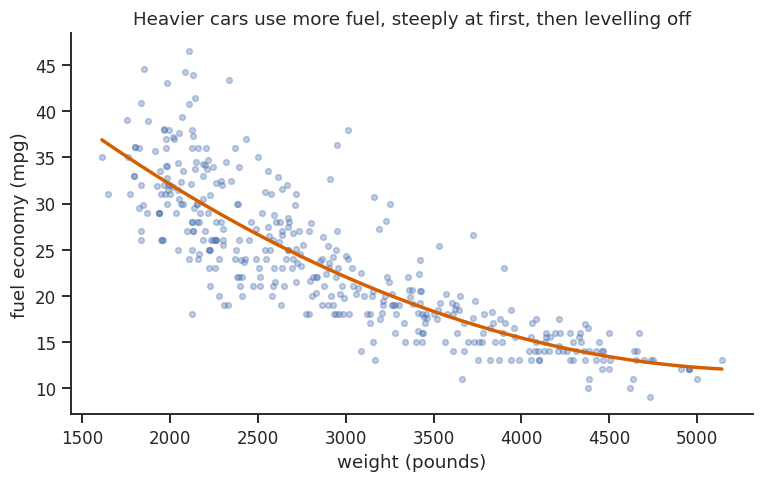

Pearson: -0.83 | Spearman: -0.87


In [11]:
# Model answer, card A, round 3
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.regplot(data=cars, x="weight", y="mpg", order=2, ci=None, scatter_kws={"alpha": 0.35, "s": 14}, line_kws={"color": OKABE_ITO[5]}, ax=ax)
ax.set(title="Heavier cars use more fuel, steeply at first, then levelling off", xlabel="weight (pounds)", ylabel="fuel economy (mpg)")
plt.show()
print("Pearson:", round(cars["weight"].corr(cars["mpg"]), 2), "| Spearman:", round(cars["weight"].corr(cars["mpg"], method="spearman"), 2))

**Model answer, card A, round 3**

**Observation:** heavier cars have much lower fuel economy; the relationship is strong, negative and curved (steep for light cars, flatter for heavy ones). **Evidence:** scatter plot with a quadratic fit; Pearson r = −0.83, Spearman ρ = −0.87 (the rank correlation is stronger because the relationship is curved). **Caveat:** weight goes with engine size and age, so this does not show that weight alone causes the difference.

### Card B (Team B answers)

**Question.** How are **horsepower** and **acceleration** (0–60 mph time) related? Describe the direction, the strength and the shape.

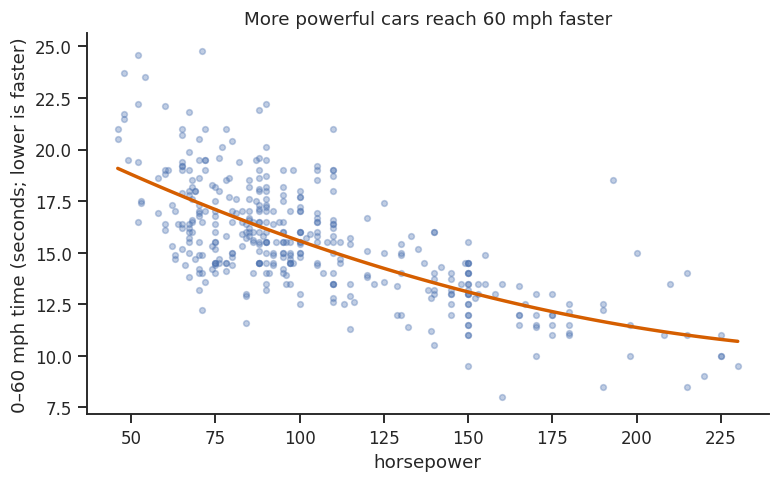

Pearson: -0.69


In [12]:
# Model answer, card B, round 3
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.regplot(data=cars, x="horsepower", y="acceleration", order=2, ci=None, scatter_kws={"alpha": 0.35, "s": 14}, line_kws={"color": OKABE_ITO[5]}, ax=ax)
ax.set(title="More powerful cars reach 60 mph faster", xlabel="horsepower", ylabel="0–60 mph time (seconds; lower is faster)")
plt.show()
print("Pearson:", round(cars["horsepower"].corr(cars["acceleration"]), 2))

**Model answer, card B, round 3**

**Observation:** more powerful cars accelerate faster (shorter 0–60 mph times); the relationship is negative and moderately strong, flattening for the most powerful cars. **Evidence:** scatter with a quadratic fit; r = −0.69. **Caveat:** acceleration also depends on weight (the hi 1200d truck in round 2); and a lower number means faster, which readers can misread, so the axis label says so.

In [13]:
# Score the OTHER team's answer for round 3 (0, 0.5 or 1), with a one-line reason
# award(3, 1, "clear observation; evidence with numbers; caveat about ...")

---
## Round 4 · Week 7 · step 5: groups and subgroups

**Hint for both cards:** A: `pd.cut` to make weight bands, then a box plot or grouped bar of mpg by band and origin (Simpson's paradox from the lecture). B: a box plot of mpg by cylinders, with the group sizes shown.

### Card A (Team A answers)

**Question.** Japanese cars have the best fuel economy overall. Is that **only because they are lighter**? Compare origins **within** weight bands.

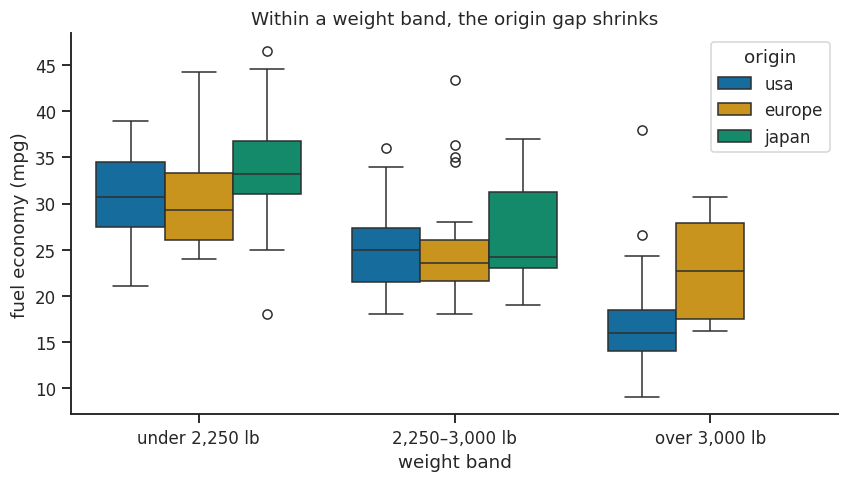

               median               count             
origin            usa europe japan    usa europe japan
weight_band                                           
under 2,250 lb   30.7   29.2  33.2   24.0   36.0  46.0
2,250–3,000 lb   25.0   23.5  24.2   67.0   24.0  33.0
over 3,000 lb    16.0   22.7   NaN  158.0   10.0   NaN


In [14]:
# Model answer, card A, round 4
cars["weight_band"] = pd.cut(cars["weight"], bins=[1500, 2250, 3000, 6000], labels=["under 2,250 lb", "2,250–3,000 lb", "over 3,000 lb"])
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=cars, x="weight_band", y="mpg", hue="origin", palette=ORIGIN_COLOURS, ax=ax)
ax.set(title="Within a weight band, the origin gap shrinks", xlabel="weight band", ylabel="fuel economy (mpg)")
plt.show()
print(cars.groupby(["weight_band", "origin"], observed=True)["mpg"].agg(["median", "count"]).unstack().round(1))

**Model answer, card A, round 4**

**Observation:** much of Japan's advantage comes from weight: overall the median Japanese car does 31.6 mpg against 18.5 for American cars, but among cars of 2,250–3,000 lb the medians are close (24.2 Japan, 25.0 USA, 23.5 Europe). **Evidence:** box plots by weight band and origin, and the median table. **Caveat:** no Japanese car weighs over 3,000 lb, so that band cannot be compared; the lightest band still shows a Japanese advantage (33.2 against 30.7 mpg).

### Card B (Team B answers)

**Question.** How does fuel economy differ by **number of cylinders**? Are any groups **too small** to trust?

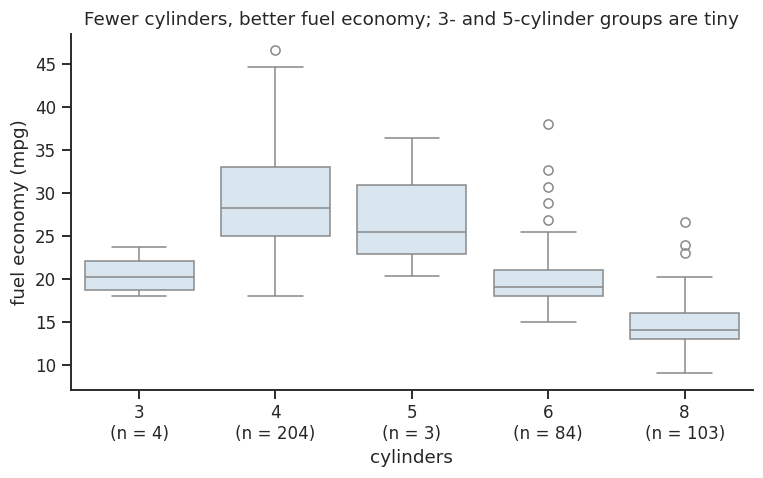

           median  count
cylinders               
3           20.25      4
4           28.25    204
5           25.40      3
6           19.00     84
8           14.00    103


In [15]:
# Model answer, card B, round 4
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.boxplot(data=cars, x="cylinders", y="mpg", color="#D6E6F2", ax=ax)
counts = cars["cylinders"].value_counts().sort_index()
ax.set_xticks(range(len(counts)), [f"{c}\n(n = {n})" for c, n in counts.items()])
ax.set(title="Fewer cylinders, better fuel economy; 3- and 5-cylinder groups are tiny", xlabel="cylinders", ylabel="fuel economy (mpg)")
plt.show()
print(cars.groupby("cylinders")["mpg"].agg(["median", "count"]))

**Model answer, card B, round 4**

**Observation:** fuel economy falls with the number of cylinders, from a median of 28.3 mpg for 4 cylinders to 19 for 6 and 14 for 8. **Evidence:** box plots with group sizes; 204 four-cylinder and 103 eight-cylinder cars. **Caveat:** the 3-cylinder (4 cars, mostly Mazda rotary engines) and 5-cylinder (3 cars) groups are too small to compare reliably; cylinders also go with weight.

In [16]:
# Score the OTHER team's answer for round 4 (0, 0.5 or 1), with a one-line reason
# award(4, 1, "clear observation; evidence with numbers; caveat about ...")

---
## ☕ Break: 10 minutes

Check the scoreboard below, and swap roles for round 5.

In [17]:
scoreboard()

Points given to Team B so far: 0


""
round


---
## Round 5 · Week 7 · step 6: time structure

**Hint for both cards:** Median by year (`groupby('year')`), drawn as a line; for B, one line per origin with direct labels. Start the y-axis at zero for honest comparisons of size.

### Card A (Team A answers)

**Question.** How did typical **fuel economy** change from 1970 to 1982? Was the change steady?

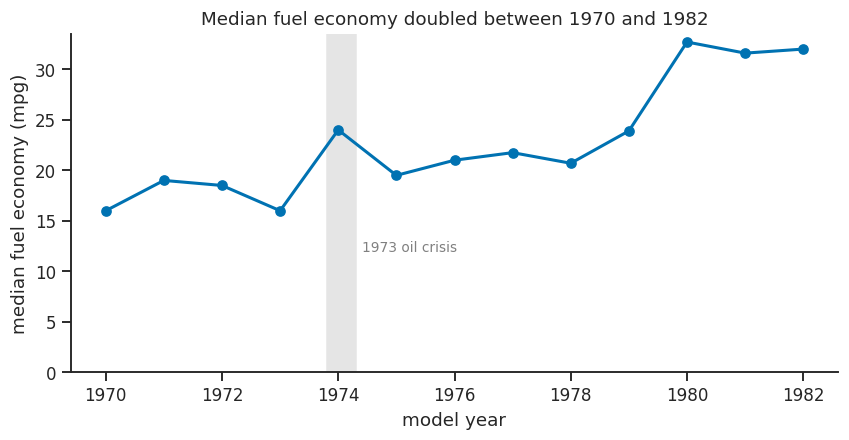

{1970: 16.0, 1976: 21.0, 1982: 32.0}


In [18]:
# Model answer, card A, round 5
yearly = cars.groupby("year")["mpg"].median()
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(yearly.index, yearly.values, marker="o", color=OKABE_ITO[0], linewidth=2)
ax.axvspan(1973.8, 1974.3, color="#E5E5E5"); ax.text(1974.4, 12, "1973 oil crisis", fontsize=9, color="grey")
ax.set(title="Median fuel economy doubled between 1970 and 1982", xlabel="model year", ylabel="median fuel economy (mpg)", ylim=(0, None))
plt.show()
print(yearly.loc[[1970, 1976, 1982]].to_dict())

**Model answer, card A, round 5**

**Observation:** median fuel economy doubled, from 16 mpg in 1970 to 32 mpg in 1982, rising fastest after the mid-1970s. **Evidence:** line of yearly medians; 16 (1970), 21 (1976), 32 (1982). **Caveat:** the sample of models changes each year (more Japanese cars later), so part of the rise is a change in which cars are in the data, not only better engineering; about 30 cars per year.

### Card B (Team B answers)

**Question.** How did typical **weight** change from 1970 to 1982, and did **every origin** follow the same path?

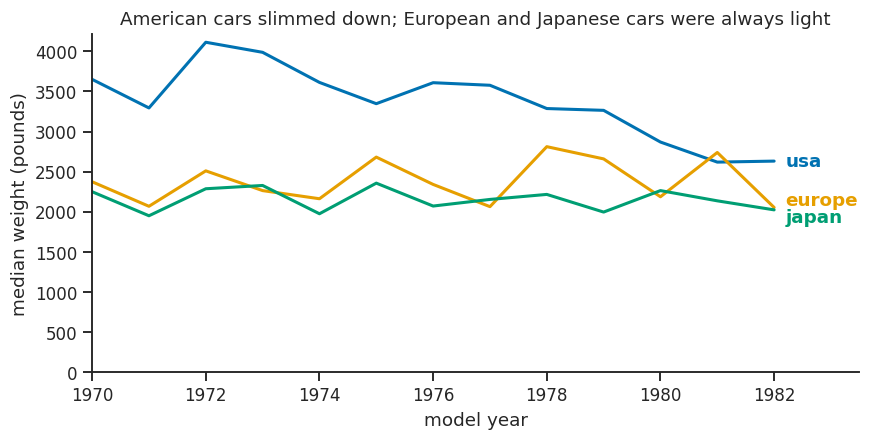

origin     usa  europe   japan
year                          
1970    3651.0  2375.0  2251.0
1982    2632.0  2055.0  2025.0


In [19]:
# Model answer, card B, round 5
w = cars.groupby(["year", "origin"], observed=True)["weight"].median().unstack()
fig, ax = plt.subplots(figsize=(9, 4))
for origin in w.columns:
    ax.plot(w.index, w[origin], color=ORIGIN_COLOURS[origin], linewidth=2)
    nudge = {"usa": 0, "europe": 90, "japan": -90}[origin]          # keep the two close labels apart
    ax.text(1982.2, w[origin].iloc[-1] + nudge, origin, color=ORIGIN_COLOURS[origin], va="center", fontweight="bold")
ax.set(title="American cars slimmed down; European and Japanese cars were always light", xlabel="model year", ylabel="median weight (pounds)", ylim=(0, None), xlim=(1970, 1983.5))
plt.show()
print(w.loc[[1970, 1982]].round(0))

**Model answer, card B, round 5**

**Observation:** American cars became much lighter (median 3,651 lb in 1970 to 2,632 lb in 1982), while European and Japanese cars stayed light throughout (about 2,000–2,400 lb). **Evidence:** median weight by year and origin, labelled directly. **Caveat:** yearly medians for Europe and Japan rest on few cars per year, so their lines are noisy.

In [20]:
# Score the OTHER team's answer for round 5 (0, 0.5 or 1), with a one-line reason
# award(5, 1, "clear observation; evidence with numbers; caveat about ...")

---
## Round 6 · Week 8: correlation heatmaps, Robinson form and seriation

**Hint for both cards:** A: `corr = complete[NUMERIC].corr()`, `D = 1 - corr.values`, then `order = seriate(D)` and `ar_events(...)` before and after. B: `complete[NUMERIC].cov()`; a diverging map centred on zero for correlation.

### Card A (Team A answers)

**Question.** Draw the **correlation heatmap** of the 7 numeric variables (use `complete`), first in the file's order, then **seriated**. Which groups of variables appear, and how much does seriation improve the order (gradient-condition violations before and after)?

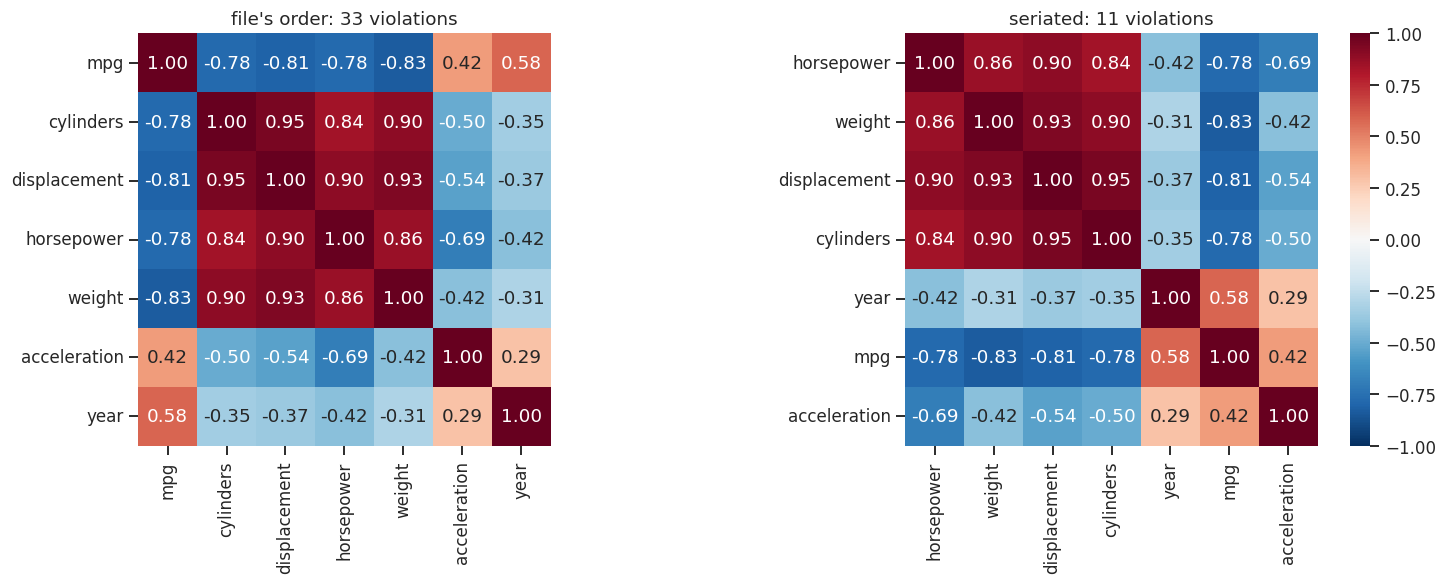

['horsepower', 'weight', 'displacement', 'cylinders', 'year', 'mpg', 'acceleration']


In [21]:
# Model answer, card A, round 6
corr = complete[NUMERIC].corr()
D = 1 - corr.values
order = seriate(D)
names = [NUMERIC[i] for i in order]
fig, axs = plt.subplots(1, 2, figsize=(13, 5.2), layout="constrained")
for ax, cols, title in [(axs[0], NUMERIC, f"file's order: {ar_events(D)} violations"),
                        (axs[1], names, f"seriated: {ar_events(D[np.ix_(order, order)])} violations")]:
    sns.heatmap(corr.loc[cols, cols], cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", square=True, cbar=ax is axs[1], ax=ax)
    ax.set_title(title)
plt.show()
print(names)

**Model answer, card A, round 6**

**Observation:** the variables form two opposing groups: an 'engine size' group (horsepower, weight, displacement, cylinders, all correlated above 0.8 with each other) against fuel economy, model year and acceleration, which are positively (more weakly) related to each other and negatively to the first group. **Evidence:** the seriated heatmap; violations fall from 33 to 11. **Caveat:** the order depends on using 1 − r and average linkage; correlation shows straight-line association only, and round 3 showed curves.

### Card B (Team B answers)

**Question.** Draw the **covariance** and the **correlation** heatmaps of the same 7 variables side by side (use `complete`). Why would the covariance heatmap mislead a reader?

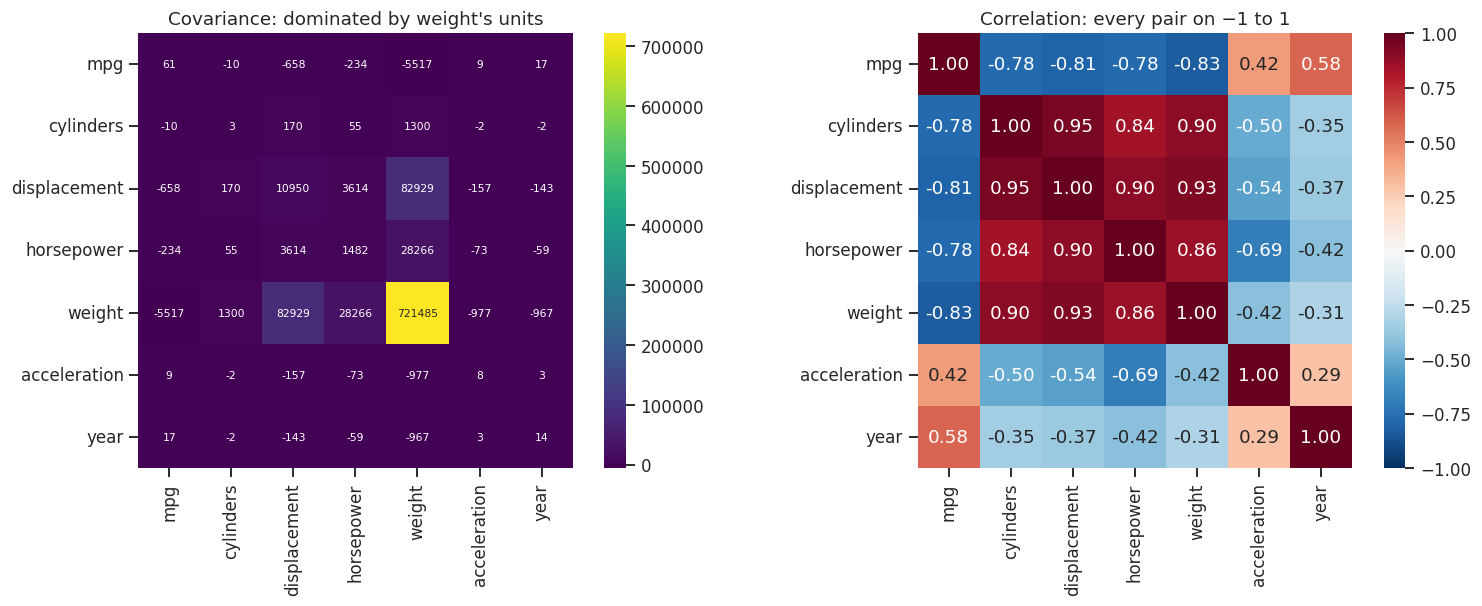

variance of weight: 721485 | variance of cylinders: 2.9


In [22]:
# Model answer, card B, round 6
fig, axs = plt.subplots(1, 2, figsize=(14, 5.4), layout="constrained")
sns.heatmap(complete[NUMERIC].cov(), cmap="viridis", annot=True, fmt=".0f", annot_kws={"size": 7}, square=True, ax=axs[0])
axs[0].set_title("Covariance: dominated by weight's units")
sns.heatmap(complete[NUMERIC].corr(), cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", square=True, ax=axs[1])
axs[1].set_title("Correlation: every pair on −1 to 1")
plt.show()
print("variance of weight:", round(complete["weight"].var()), "| variance of cylinders:", round(complete["cylinders"].var(), 1))

**Model answer, card B, round 6**

**Observation:** the covariance heatmap is dominated by weight, whose variance (about 720,000 square pounds) dwarfs every other entry, so all other cells look alike; the correlation heatmap shows the real pattern, for example mpg strongly negative with weight (−0.83) and displacement. **Evidence:** the two heatmaps side by side. **Caveat:** covariance is still the right quantity when units matter (for example, in a model in pounds); the problem is reading it as strength of association.

In [23]:
# Score the OTHER team's answer for round 6 (0, 0.5 or 1), with a one-line reason
# award(6, 1, "clear observation; evidence with numbers; caveat about ...")

---
## Round 7 · Week 8: clustered heatmaps and k-means

**Hint for both cards:** A: `sns.clustermap(Z, method='ward', row_colors=...)`, then `fcluster(..., 3, 'maxclust')` and `pd.crosstab` with origin. B: `silhouette_score` for k = 2 to 7; `KMeans(n_clusters=k, n_init=10, random_state=445)`; sort the distance matrix by the labels.

### Card A (Team A answers)

**Question.** Draw a **clustered heatmap** of the cars × standardised variables (`Z`), with a strip showing each car's **origin** (added only as a check). Into how many main groups do the cars fall, and do they match origin?

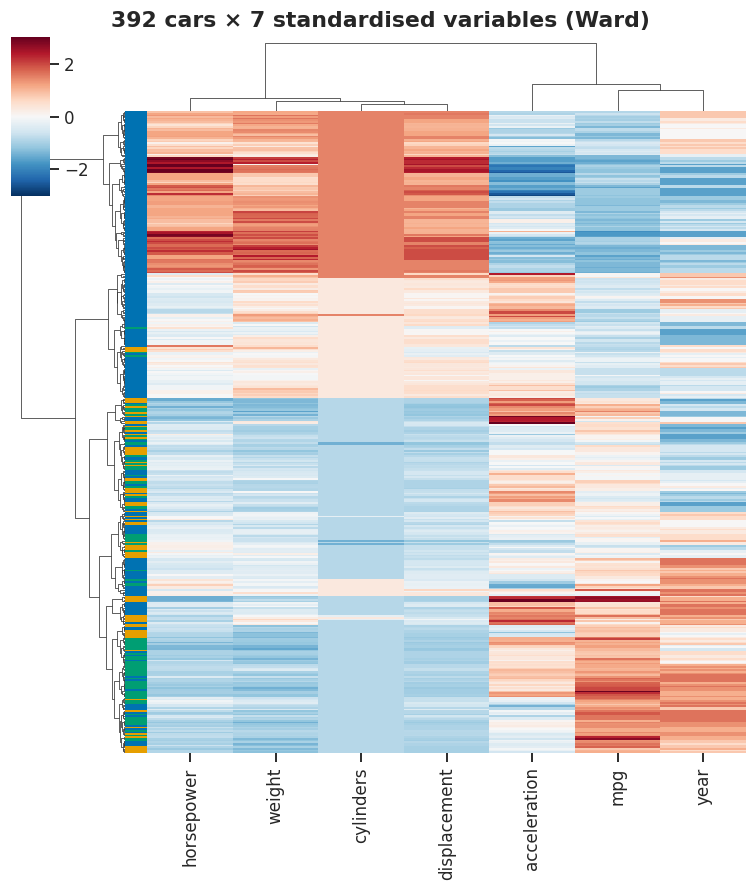

origin  usa  europe  japan
group                     
1        99       0      0
2        70       3      3
3        76      65     76
    mpg  cylinders  weight    year
1  14.0        8.0  4154.0  1973.0
2  19.0        6.0  3280.0  1975.5
3  28.0        4.0  2265.0  1978.0


In [24]:
# Model answer, card A, round 7
row_colours = complete["origin"].map(ORIGIN_COLOURS).astype(str).values
g = sns.clustermap(Z, method="ward", metric="euclidean", cmap="RdBu_r", vmin=-3, vmax=3, center=0,
                   row_colors=row_colours, yticklabels=False, figsize=(7, 8), dendrogram_ratio=(0.15, 0.1))
g.figure.suptitle("392 cars × 7 standardised variables (Ward)", y=1.01, fontweight="bold")
plt.show()
groups = fcluster(g.dendrogram_row.linkage, t=3, criterion="maxclust")
print(pd.crosstab(pd.Series(groups, name="group"), complete["origin"]))
print(complete.groupby(groups)[["mpg", "cylinders", "weight", "year"]].median())

**Model answer, card A, round 7**

**Observation:** the cars split into three main groups that follow engine size more than origin: large, heavy, low-mpg cars (all American), mid-sized cars (mostly American), and small economical cars (all European and Japanese cars, plus some American ones). **Evidence:** the clustered heatmap with the origin strip, and the cross-table (one group of 99 cars is entirely American; another holds all European and Japanese cars except 6). **Caveat:** Ward linkage and three groups were chosen; origin is mixed into the small-car group, so the clusters describe car size, not nationality.

### Card B (Team B answers)

**Question.** Use **k-means** on `Z`: choose k with the **silhouette**, then **reorder the distance matrix** by cluster. Describe the clusters (for example by cylinders and mpg).

{2: np.float64(0.481), 3: np.float64(0.354), 4: np.float64(0.349), 5: np.float64(0.33), 6: np.float64(0.276), 7: np.float64(0.273)} -> best k = 2


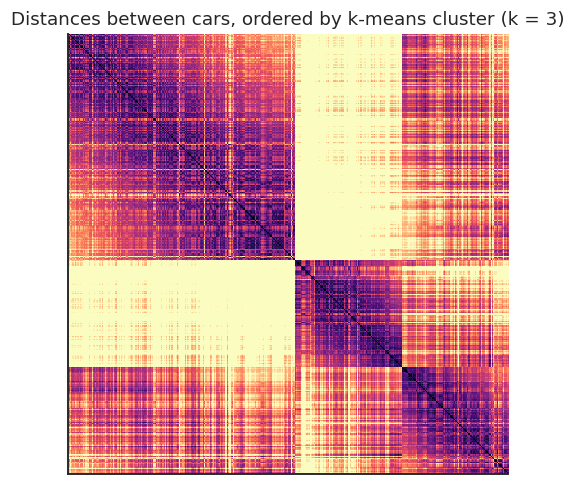

cylinders  3    4  5   6   8
row_0                       
0          4  195  1   2   0
1          0    0  0   0  95
2          0    4  2  81   8
    mpg  weight    year
0  29.0  2232.0  1978.0
1  14.0  4190.0  1973.0
2  19.0  3245.0  1976.0


In [25]:
# Model answer, card B, round 7
sil = {k: silhouette_score(Z, KMeans(n_clusters=k, n_init=10, random_state=445).fit_predict(Z)) for k in range(2, 8)}
k_best = max(sil, key=sil.get)
print({k: round(v, 3) for k, v in sil.items()}, "-> best k =", k_best)
k_used = 3                                                    # 2 is best, but 3 is close and more informative (see caveat)
labels = KMeans(n_clusters=k_used, n_init=10, random_state=445).fit_predict(Z)
D_cars = squareform(pdist(Z.values)); o = np.argsort(labels, kind="stable")
fig, ax = plt.subplots(figsize=(6, 5.2))
ax.imshow(D_cars[np.ix_(o, o)], cmap="magma", vmax=np.percentile(D_cars, 75), interpolation="none")
ax.set(title=f"Distances between cars, ordered by k-means cluster (k = {k_used})", xticks=[], yticks=[])
plt.show()
print(pd.crosstab(labels, complete["cylinders"]))
print(complete.groupby(labels)[["mpg", "weight", "year"]].median())

**Model answer, card B, round 7**

**Observation:** the silhouette is highest for k = 2 (0.48), but k = 3 (0.35) gives three interpretable clusters that appear as dark blocks on the reordered distance matrix: 8-cylinder heavy cars (median 14 mpg), 6-cylinder mid-sized cars (19 mpg) and 4-cylinder light cars (29 mpg). **Evidence:** silhouette values, the reordered distance matrix and the cross-table with cylinders. **Caveat:** k was chosen partly for interpretation, not only the silhouette; k-means always finds k clusters, even without real groups.

In [26]:
# Score the OTHER team's answer for round 7 (0, 0.5 or 1), with a one-line reason
# award(7, 1, "clear observation; evidence with numbers; caveat about ...")

---
## Round 8 · Week 8: spectral seriation

**Hint for both cards:** Correlate the Fiedler vector with each variable (`np.corrcoef`), then plot that variable in spectral order. B: plot year along the order, coloured by origin.

### Card A (Team A answers)

**Question.** Use **spectral seriation** (`fiedler_order(Z.values)`) to order the cars. Which **variable** does the gradient follow most closely? Show it.

{'mpg': 0.79, 'cylinders': -0.98, 'displacement': -0.96, 'horsepower': -0.9, 'weight': -0.91, 'acceleration': 0.57, 'year': 0.39}


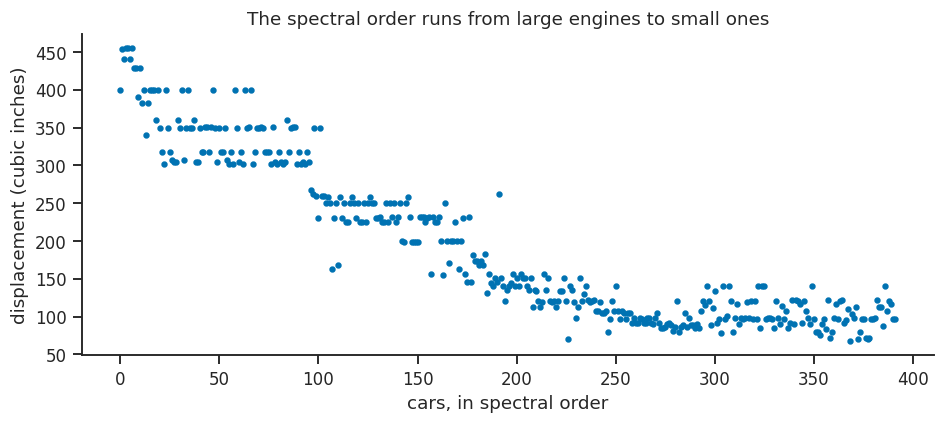

violations: random 9922953 | spectral 4044796


In [27]:
# Model answer, card A, round 8
fiedler, order = fiedler_order(Z.values)
links = {v: float(np.corrcoef(fiedler, complete[v])[0, 1]) for v in NUMERIC}
print({v: round(r, 2) for v, r in links.items()})
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.scatter(range(len(order)), complete["displacement"].values[order], s=10, color=OKABE_ITO[0])
ax.set(title="The spectral order runs from large engines to small ones", xlabel="cars, in spectral order", ylabel="displacement (cubic inches)")
plt.show()
D_cars = squareform(pdist(Z.values))
print("violations: random", ar_events(D_cars[np.ix_(np.random.default_rng(1).permutation(len(Z)), np.random.default_rng(1).permutation(len(Z)))]),
      "| spectral", ar_events(D_cars[np.ix_(order, order)]))

**Model answer, card A, round 8**

**Observation:** the spectral order is a gradient of engine size: it follows the number of cylinders and the displacement most closely, from large engines to small ones (the direction can be reversed, since an eigenvector's sign is arbitrary). **Evidence:** the Fiedler vector correlates about −0.98 with cylinders, −0.96 with displacement, −0.91 with weight and −0.90 with horsepower, and +0.79 with mpg; violations fall from about 9.9 million (random order) to about 4.0 million. **Caveat:** the gradient depends on the 10-nearest-neighbour graph and on standardising; it summarises one direction only.

### Card B (Team B answers)

**Question.** Use **spectral seriation** to order the cars. How do **model year** and **origin** vary along the spectral order? Show it.

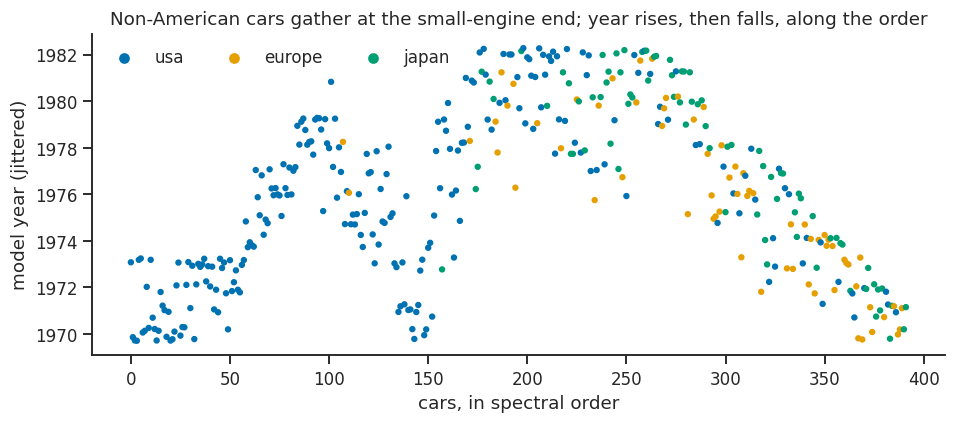

correlation of Fiedler value with year: 0.39
usa      -0.023
europe    0.039
japan     0.039
dtype: float64


In [28]:
# Model answer, card B, round 8
fiedler, order = fiedler_order(Z.values)
ordered = complete.iloc[order].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.scatter(ordered.index, ordered["year"] + np.random.default_rng(0).uniform(-0.3, 0.3, len(ordered)), s=10,
           c=ordered["origin"].map(ORIGIN_COLOURS))
for o, c in ORIGIN_COLOURS.items():
    ax.scatter([], [], color=c, label=o)
ax.legend(frameon=False, ncol=3)
ax.set(title="Non-American cars gather at the small-engine end; year rises, then falls, along the order", xlabel="cars, in spectral order", ylabel="model year (jittered)")
plt.show()
print("correlation of Fiedler value with year:", round(np.corrcoef(fiedler, complete["year"])[0, 1], 2))
print(pd.Series(fiedler).groupby(complete["origin"].values, observed=True).mean().round(3))

**Model answer, card B, round 8**

**Observation:** European and Japanese cars are concentrated at the small-engine end of the spectral order, while American cars spread along all of it; model year is not a simple gradient: the large-engine end is mostly early-1970s cars, the newest cars sit in the middle-to-small range, and the small-engine end mixes old and new small cars. **Evidence:** year in spectral order coloured by origin; the Fiedler vector correlates about 0.39 with year, and its mean is higher for Europe and Japan (0.039) than for the USA (−0.023). **Caveat:** the gradient is mainly engine size (card A); a correlation of 0.39 understates a relationship that rises and then falls (Anscombe again); the direction of the order is arbitrary.

In [29]:
# Score the OTHER team's answer for round 8 (0, 0.5 or 1), with a one-line reason
# award(8, 1, "clear observation; evidence with numbers; caveat about ...")

---
## Final question (both teams): the tie-break

**Model answer.** *Observation:* lighter cars with smaller engines were the most fuel-efficient, and cars of every origin became more efficient through the 1970s. *Evidence:* weight and mpg correlate at −0.83 (round 3); median mpg doubled from 16 to 32 between 1970 and 1982 (round 5); the seriated correlation heatmap groups engine size and weight against mpg (round 6). *Caveat:* origin matters less than it first appears once weight is taken into account (round 4); these are associations in 392 cars, not a guarantee for any particular car.

In [30]:
# Model answer: see the rounds above; any one clear chart (for example round 3, card A) supports it

*(model answer above)*

---
## Results

Run the cell below to see the scores your team gave the other team, and save them to a file. **Send the file to the tutor** (or post it in the Moodle forum): the tutor adds the two teams' files to find the winner.

In [31]:
board = scoreboard()
with open(f"scores_given_by_team_{MY_TEAM}.json", "w") as f:
    json.dump({"team": MY_TEAM, "team_name": TEAM_NAME, "scores_given_to": OTHER_TEAM, "scores": SCORES_GIVEN}, f, indent=2)
print(f"saved scores_given_by_team_{MY_TEAM}.json")
board

Points given to Team B so far: 0
saved scores_given_by_team_A.json


""
round


### References

* Quinlan, J. R. (1993). Combining instance-based and model-based learning. *Proceedings of the Tenth International Conference on Machine Learning*, 236–243. Data: UCI Machine Learning Repository, Auto MPG, [doi:10.24432/C5859H](https://doi.org/10.24432/C5859H).
* The Week 7 lecture (the EDA protocol; observation, evidence, caveat) and the Week 8 lecture (seriation, clustering, spectral methods); the ST445 visualisation checklist (Appendix B).